<a href="https://colab.research.google.com/github/ishikabeniwal/CSET343/blob/main/Assignment9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install torch torchvision opencv-python
!pip install numpy pandas matplotlib scikit-learn seaborn


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Resume_Ishika.pdf', 'Colab Notebooks', 'chest_xray', 'UR_fall_detection_dataset_cam0_rgb']


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/UR_fall_detection_dataset_cam0_rgb"

print(os.path.exists(DATASET_PATH))
print(os.listdir(DATASET_PATH))

True
['adl-07-cam0-rgb', 'fall-14-cam0-rgb', 'adl-38-cam0-rgb', 'fall-20-cam0-rgb', 'adl-33-cam0-rgb', 'fall-21-cam0-rgb', 'fall-15-cam0-rgb', 'adl-32-cam0-rgb', 'adl-06-cam0-rgb', 'adl-39-cam0-rgb', 'fall-04-cam0-rgb', 'fall-09-cam0-rgb', 'adl-24-cam0-rgb', 'fall-05-cam0-rgb', 'adl-11-cam0-rgb', 'adl-10-cam0-rgb', 'fall-03-cam0-rgb', 'fall-08-cam0-rgb', 'adl-25-cam0-rgb', 'fall-02-cam0-rgb', 'adl-29-cam0-rgb', 'adl-23-cam0-rgb', 'adl-35-cam0-rgb', 'adl-34-cam0-rgb', 'adl-28-cam0-rgb', 'fall-30-cam0-rgb', 'fall-13-cam0-rgb', 'adl-16-cam0-rgb', 'adl-22-cam0-rgb', 'adl-17-cam0-rgb', 'fall-27-cam0-rgb', 'fall-01-cam0-rgb', 'adl-12-cam0-rgb', 'adl-13-cam0-rgb', 'fall-18-cam0-rgb', 'adl-26-cam0-rgb', 'fall-12-cam0-rgb', 'fall-26-cam0-rgb', 'adl-01-cam0-rgb', 'fall-19-cam0-rgb', 'adl-30-cam0-rgb', 'adl-27-cam0-rgb', 'fall-17-cam0-rgb', 'adl-05-cam0-rgb', 'adl-04-cam0-rgb', 'adl-18-cam0-rgb', 'adl-31-cam0-rgb', 'adl-19-cam0-rgb', 'fall-23-cam0-rgb', 'fall-22-cam0-rgb', 'fall-25-cam0-rgb', 'fa

In [ ]:

import os
import cv2
import numpy as np
import random
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Configuration
DATASET_PATH = "URFD"

NUM_FRAMES = 16
IMG_SIZE = 112
BATCH_SIZE = 2
EPOCHS = 15

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", DEVICE)


In [ ]:
all_paths = []
all_labels = []

for folder in os.listdir(DATASET_PATH):

    folder_path = os.path.join(DATASET_PATH, folder)

    if not os.path.isdir(folder_path):
        continue

    if folder.startswith("fall"):
        all_paths.append(folder_path)
        all_labels.append(1)

    elif folder.startswith("adl"):
        all_paths.append(folder_path)
        all_labels.append(0)

print("Total samples:", len(all_paths))
print("Fall:", all_labels.count(1))
print("ADL:", all_labels.count(0))

Total samples: 70
Fall: 30
ADL: 40


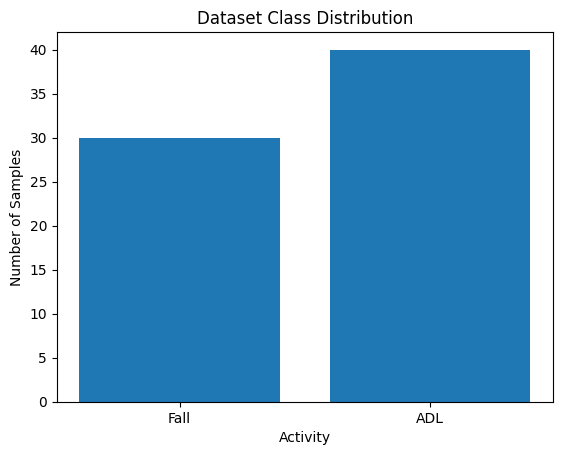

In [ ]:
plt.bar(
    ["Fall", "ADL"],
    [all_labels.count(1), all_labels.count(0)]
)

plt.title("Dataset Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.show()

In [ ]:

train_paths, test_paths, train_labels, test_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.2,
    random_state=42,
    stratify=all_labels
)

print("Training samples:", len(train_paths))
print("Testing samples:", len(test_paths))


Training samples: 56
Testing samples: 14


In [ ]:

class FallDataset(Dataset):

    def __init__(self, paths, labels):
        self.paths = paths
        self.labels = labels

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):

        folder = self.paths[index]

        image_files = sorted([
            f for f in os.listdir(folder)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])

        frames = []

        for file in image_files:

            image_path = os.path.join(folder, file)

            img = cv2.imread(image_path)

            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (112, 112))
                frames.append(img)

        if len(frames) == 0:
            raise RuntimeError("No valid images in: " + folder)

        # Select 16 equally spaced frames
        indices = np.linspace(
            0, len(frames) - 1, 16, dtype=int
        )

        frames = [frames[i] for i in indices]

        video = np.array(frames)

        # Convert to PyTorch tensor
        video = torch.tensor(video, dtype=torch.float32)

        # Shape: (Channels, Frames, Height, Width)
        video = video.permute(3, 0, 1, 2)

        video = video / 255.0

        label = torch.tensor(self.labels[index], dtype=torch.long)

        return video, label


In [ ]:

train_dataset = FallDataset(train_paths, train_labels)
test_dataset = FallDataset(test_paths, test_labels)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")


DataLoaders created successfully!


In [ ]:

frames, labels = next(iter(train_loader))

print("Frames shape:", frames.shape)
print("Labels shape:", labels.shape)


Frames shape: torch.Size([4, 3, 16, 112, 112])
Labels shape: torch.Size([4])


In [ ]:

class CNN3D(nn.Module):

    def __init__(self):

        super(CNN3D, self).__init__()

        self.features = nn.Sequential(

            # First 3D convolution
            nn.Conv3d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=2),

            # Second 3D convolution
            nn.Conv3d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=2),

            # Third 3D convolution
            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool3d((1, 1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 2)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


model = CNN3D().to(DEVICE)

print(model)


CNN3D(
  (features): Sequential(
    (0): Conv3d(3, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): ReLU()
    (2): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (4): ReLU()
    (5): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool3d(output_size=(1, 1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

In [ ]:

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5


In [ ]:

train_losses = []

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0

    for videos, labels_batch in train_loader:

        videos = videos.to(DEVICE)
        labels_batch = labels_batch.to(DEVICE)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(videos)

        # Calculate loss
        loss = criterion(outputs, labels_batch)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}], "
        f"Loss: {epoch_loss:.4f}"
    )


NameError: name 'EPOCHS' is not defined

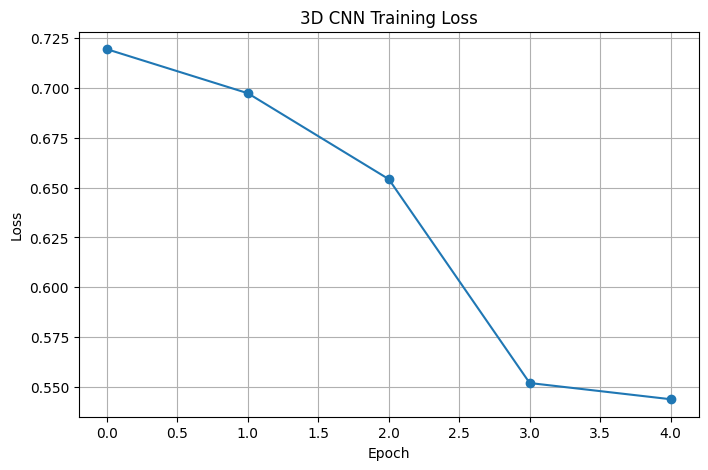

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(train_losses, marker='o')

plt.title("3D CNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)
plt.show()


In [ ]:

model.eval()

y_true = []
y_pred = []
y_scores = []

with torch.no_grad():

    for videos, labels_batch in test_loader:

        videos = videos.to(DEVICE)

        outputs = model(videos)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels_batch.numpy())

        y_pred.extend(predictions.cpu().numpy())

        # Probability of Fall (class 1)
        y_scores.extend(
            probabilities[:, 1].cpu().numpy()
        )


print("Accuracy:",
      accuracy_score(y_true, y_pred))

print("Precision:",
      precision_score(y_true, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_true, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_true, y_pred, zero_division=0))

if len(set(y_true)) == 2:
    print("AUROC:", roc_auc_score(y_true, y_scores))
else:
    print("AUROC: Cannot calculate (only one class in test set)")


NameError: name 'model' is not defined

In [ ]:

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Fall'],
    yticklabels=['Normal', 'Fall']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


In [ ]:

print(classification_report(
    y_true,
    y_pred,
    target_names=['Normal Activity', 'Fall']
))


In [ ]:

torch.save(
    model.state_dict(),
    "fall_detection_3dcnn.pth"
)

print("Model saved successfully!")


In [ ]:

loaded_model = CNN3D().to(DEVICE)

loaded_model.load_state_dict(
    torch.load(
        "fall_detection_3dcnn.pth",
        map_location=DEVICE
    )
)

loaded_model.eval()

print("Model loaded successfully!")
